# RIAL on the Switch riddle (prisoners and light bulb)

Notebook version of *Learning to Communicate with Deep Multi-Agent Reinforcement Learning* (Foerster, Assael et al., NIPS 2016), RIAL with parameter sharing, Switch task only.

**Run all cells top to bottom.** PyTorch and matplotlib come preinstalled on Colab. This model is tiny, so a CPU runtime is fine; a GPU is not needed.

In [1]:
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F

N_U, N_M, D = 2, 2, 128  # |U|, |M|, hidden/embedding size

## 1. Environment
Vectorised over B parallel games. One random prisoner enters the room each day; only they see and set the switch.

In [2]:
class SwitchEnv:
    """Vectorised over B parallel episodes. One random prisoner per day enters the room."""

    def __init__(self, n, B, device):
        self.n, self.B, self.dev = n, B, device
        self.T = 4 * n - 6  # horizon from the paper

    def reset(self):
        self.t = 0
        self.visited = torch.zeros(self.B, self.n, dtype=torch.bool, device=self.dev)
        self.switch = torch.zeros(self.B, dtype=torch.long, device=self.dev)  # starts Off
        self.done = torch.zeros(self.B, dtype=torch.bool, device=self.dev)
        self._draw()

    def _draw(self):
        self.active = torch.randint(0, self.n, (self.B,), device=self.dev)
        self.visited[torch.arange(self.B, device=self.dev), self.active] = True

    def observe(self):
        is_active = F.one_hot(self.active, self.n).bool()            # (B,n)
        o = is_active.float().unsqueeze(-1)                          # (B,n,1): "am I in the room?"
        sw = F.one_hot(self.switch, N_M).float().unsqueeze(1)        # (B,1,2)
        msg_in = sw * o                                              # only the agent in the room sees the switch
        return o, msg_in, is_active

    def step(self, u, m):
        """u, m: (B,n) long. Only the active agent's u/m affect the world."""
        a = self.active[:, None]
        u_a, m_a = u.gather(1, a).squeeze(1), m.gather(1, a).squeeze(1)
        alive = ~self.done
        tell = (u_a == 1) & alive
        all_visited = self.visited.all(1)
        r = torch.zeros(self.B, device=self.dev)
        r[tell & all_visited] = 1.0
        r[tell & ~all_visited] = -1.0
        last = self.t == self.T - 1
        step_done = tell | torch.full_like(tell, last)
        self.switch = torch.where(alive & ~tell, m_a, self.switch)   # active agent sets the switch
        self.done = self.done | step_done
        self.t += 1
        if not last:
            self._draw()
        return r, step_done


def oracle_return(n, T, trials=200_000):
    """Best average return with access to the true state: Tell the moment everyone has visited."""
    draws = torch.randint(0, n, (trials, T))
    return F.one_hot(draws, n).any(1).all(1).float().mean().item()

## 2. Model
Shared network: embeddings summed into `z`, a 2-layer GRU, then an MLP head with `|U|+|M|` Q-values.

In [3]:
class RIALNet(nn.Module):
    def __init__(self, n_agents, d=D, use_bn=False):
        super().__init__()
        self.task = nn.Linear(1, d)                                   # TaskMLP for the 1-bit observation
        self.msg_bn = nn.BatchNorm1d(N_M) if use_bn else nn.Identity()
        self.msg = nn.Linear(N_M, d)                                  # MLP[|M|,128] on incoming message
        self.u_emb = nn.Embedding(N_U + 1, d)                         # +1 = "start" token
        self.m_emb = nn.Embedding(N_M + 1, d)                         # own previous message
        self.a_emb = nn.Embedding(n_agents, d)                        # agent index -> specialisation
        self.rnn = nn.GRU(d, d, num_layers=2)
        self.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, N_U + N_M))

    def forward(self, o, msg_in, u_prev, m_prev, agent_id, h):
        z = (self.task(o) + self.msg(self.msg_bn(msg_in)) + self.u_emb(u_prev)
             + self.m_emb(m_prev) + self.a_emb(agent_id))
        y, h = self.rnn(z.unsqueeze(0), h)
        out = self.head(y.squeeze(0))
        return out[:, :N_U], out[:, N_U:], h


def eps_greedy(q, legal, eps):
    greedy = q.masked_fill(~legal, -1e9).argmax(-1)
    rand = torch.multinomial(legal.float().view(-1, q.size(-1)), 1).view(greedy.shape)
    explore = torch.rand(greedy.shape, device=q.device) < eps
    return torch.where(explore, rand, greedy)

## 3. Rollout
`rollout` plays episodes with the online net and records everything; `unroll_target` replays the recorded inputs through the target net.

In [4]:
def rollout(net, env, eps):
    B, n, dev = env.B, env.n, env.dev
    env.reset()
    ids = torch.arange(n, device=dev).repeat(B)                       # agents flattened into the batch
    h = torch.zeros(2, B * n, D, device=dev)
    u_prev = torch.full((B, n), N_U, dtype=torch.long, device=dev)
    m_prev = torch.full((B, n), N_M, dtype=torch.long, device=dev)
    keys = ["o", "msg", "up", "mp", "legal", "qu", "qm", "r", "done", "u", "m"]
    rec = {k: [] for k in keys}
    for _ in range(env.T):
        o, msg_in, active = env.observe()
        qu, qm, h = net(o.view(-1, 1), msg_in.view(-1, N_M), u_prev.view(-1), m_prev.view(-1), ids, h)
        qu, qm = qu.view(B, n, N_U), qm.view(B, n, N_M)
        legal = torch.stack([torch.ones_like(active), active], -1)    # Tell only legal in the room
        u = eps_greedy(qu, legal, eps)
        m = eps_greedy(qm, torch.ones_like(qm, dtype=torch.bool), eps)
        r, done = env.step(u, m)
        for k, v in zip(keys, [o, msg_in, u_prev, m_prev, legal,
                               qu.gather(-1, u[..., None]).squeeze(-1),
                               qm.gather(-1, m[..., None]).squeeze(-1), r, done, u, m]):
            rec[k].append(v)
        u_prev, m_prev = u, m
    return {k: torch.stack(v) for k, v in rec.items()}                # each (T,B,...)


@torch.no_grad()
def unroll_target(net, ro):
    T, B, n = ro["up"].shape
    ids = torch.arange(n, device=ro["up"].device).repeat(B)
    h = torch.zeros(2, B * n, D, device=ro["up"].device)
    qus, qms = [], []
    for t in range(T):
        qu, qm, h = net(ro["o"][t].reshape(-1, 1), ro["msg"][t].reshape(-1, N_M),
                        ro["up"][t].reshape(-1), ro["mp"][t].reshape(-1), ids, h)
        qus.append(qu.view(B, n, N_U))
        qms.append(qm.view(B, n, N_M))
    return torch.stack(qus), torch.stack(qms)

## 4. Inspecting behaviour
`show_episodes` prints day-by-day greedy play; `protocol_table` summarises the learned protocol.

In [5]:
def alive_mask(done):
    """(T,B) bool done flags -> (T,B) bool: is the episode still running at step t?"""
    first = torch.ones_like(done[:1]).float()
    return torch.cat([first, (~done).float().cumprod(0)[:-1]]).bool()


@torch.no_grad()
def greedy_rollout(net, n, B):
    env = SwitchEnv(n, B, next(net.parameters()).device)
    net.eval()
    ro = rollout(net, env, 0.0)  # eps = 0: pure greedy, what the agents have learned
    net.train()
    return env, {k: v.cpu() for k, v in ro.items()}


def show_episodes(net, n, k=5):
    """Print day-by-day what happened in k greedy episodes."""
    env, ro = greedy_rollout(net, n, k)
    alive = alive_mask(ro["done"])
    SW, U = ["Off", "On"], ["None", "Tell"]
    for b in range(k):
        print(f"\n--- Episode {b + 1} ---")
        print("day | in room | switch seen | visited | action | sets switch to | reward")
        seen = set()
        for t in range(env.T):
            if not alive[t, b]:
                break
            a = ro["o"][t, b, :, 0].argmax().item()               # who is in the room
            seen.add(a)
            sw = ro["msg"][t, b, a].argmax().item()               # switch state they see
            u, m = ro["u"][t, b, a].item(), ro["m"][t, b, a].item()
            r = ro["r"][t, b].item()
            sets = "-" if u == 1 else SW[m]                       # message ignored after Tell
            print(f"{t + 1:3d} | P{a:<6d} | {SW[sw]:<11} | {len(seen)}/{n}     | {U[u]:<6} | {sets:<14} | {r:+.0f}")


def protocol_table(net, n, episodes=1000):
    """Summarise the learned protocol: what does a prisoner do, given the day,
    whether they've been in the room before, and the switch they see?"""
    env, ro = greedy_rollout(net, n, episodes)
    alive = alive_mask(ro["done"])
    B, idx = episodes, torch.arange(episodes)
    been = torch.zeros(B, n, dtype=torch.bool)
    stats = {}  # (day, been_before, switch) -> [count, tells, non_tells, set_on]
    for t in range(env.T):
        a = ro["o"][t, :, :, 0].argmax(-1)
        sw = ro["msg"][t][idx, a].argmax(-1)
        was = been[idx, a]
        u, m = ro["u"][t][idx, a], ro["m"][t][idx, a]
        for b in range(B):
            if alive[t, b]:
                s = stats.setdefault((t + 1, bool(was[b]), int(sw[b])), [0, 0, 0, 0])
                s[0] += 1
                if u[b] == 1:
                    s[1] += 1
                else:
                    s[2] += 1
                    s[3] += int(m[b])
        been[idx, a] = True
    print(f"\n--- Learned protocol ({episodes} greedy episodes) ---")
    print("day | been here before | switch seen | count | % Tell | % set switch On (when not telling)")
    for (day, was, sw), (c, tells, non, on) in sorted(stats.items()):
        on_pct = f"{100 * on / non:5.1f}" if non else "  -  "
        print(f"{day:3d} | {str(was):<16} | {['Off', 'On'][sw]:<11} | {c:5d} | {100 * tells / c:5.1f}  | {on_pct}")

## 5. Plotting

In [6]:
def plot_curve(history, path, title):
    import matplotlib.pyplot as plt

    epochs, norm = zip(*history)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, norm, label="RIAL")
    plt.axhline(1.0, color="k", linestyle="--", linewidth=1, label="Oracle")
    plt.xlabel("# Epochs")
    plt.ylabel("Norm. R (Optimal)")
    plt.title(title)
    plt.ylim(min(0.0, min(norm)) - 0.05, 1.05)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150)
        print(f"saved plot to {path}")
    plt.show()

## 6. Training loop

In [7]:
def train(args):

    torch.manual_seed(args.seed)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    env = SwitchEnv(args.n, args.batch, dev)
    eval_env = SwitchEnv(args.n, 1000, dev)
    net = RIALNet(args.n, use_bn=args.bn).to(dev)
    tgt = copy.deepcopy(net).eval()
    opt = torch.optim.RMSprop(net.parameters(), lr=args.lr)
    oracle = oracle_return(args.n, env.T)
    print(f"n={args.n} T={env.T} oracle return={oracle:.3f}")
    history = []  # (epoch, normalised return)

    for ep in range(1, args.epochs + 1):
        ro = rollout(net, env, args.eps)
        with torch.no_grad():
            tqu, tqm = unroll_target(tgt, ro)
            nxt_u = tqu.masked_fill(~ro["legal"], -1e9).max(-1).values   # (T,B,n)
            nxt_m = tqm.max(-1).values
            nxt_u = torch.cat([nxt_u[1:], torch.zeros_like(nxt_u[:1])])  # value at t+1
            nxt_m = torch.cat([nxt_m[1:], torch.zeros_like(nxt_m[:1])])
            not_done = (~ro["done"]).float().unsqueeze(-1)
            r = ro["r"].unsqueeze(-1)
            y_u = r + args.gamma * not_done * nxt_u
            y_m = r + args.gamma * not_done * nxt_m
            alive = torch.cat([torch.ones_like(ro["r"][:1]),
                               (~ro["done"]).float().cumprod(0)[:-1]]).unsqueeze(-1)  # (T,B,1)

        loss = (((ro["qu"] - y_u) ** 2 + (ro["qm"] - y_m) ** 2) * alive).sum() / args.batch
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), args.clip)
        opt.step()

        if ep % args.target_every == 0:
            tgt.load_state_dict(net.state_dict())
        if ep % args.eval_every == 0:
            net.eval()
            with torch.no_grad():
                er = rollout(net, eval_env, 0.0)["r"].sum(0).mean().item()
            net.train()
            history.append((ep, er / oracle))
            print(f"epoch {ep:5d}  loss {loss.item():8.4f}  eval return {er:.3f}  normalised {er / oracle:.3f}")

    if history and args.plot:
        plot_curve(history, args.plot, f"RIAL on Switch (n={args.n})")

    if args.trace > 0:
        show_episodes(net, args.n, args.trace)
        protocol_table(net, args.n)

    return net, history

## 7. Configure and run
Edit the values below, then run the next cell. For n=4 use `n=4, epochs=40000` (takes much longer).

In [8]:
from types import SimpleNamespace

args = SimpleNamespace(
    n=3,                # number of prisoners (paper: 3 and 4)
    epochs=5000,        # 1 epoch = 1 batch of parallel episodes + 1 gradient step (paper: ~5k for n=3, ~40k for n=4)
    batch=32,           # parallel episodes per update
    lr=5e-4,            # RMSProp learning rate
    eps=0.05,           # epsilon-greedy
    gamma=1.0,          # discount
    target_every=100,   # target-network refresh interval (epochs)
    clip=10.0,          # grad-norm clip (my addition, not in the paper)
    bn=False,           # batch norm on incoming message
    eval_every=100,     # evaluate/print every k epochs
    seed=0,
    plot="rial_switch.png",  # "" to skip saving (the plot is still shown)
    trace=5,            # episodes to print after training (0 = off)
)

n=3 T=6 oracle return=0.741
epoch   100  loss   5.0651  eval return 0.266  normalised 0.359
epoch   200  loss   2.9940  eval return 0.349  normalised 0.471
epoch   300  loss   4.7354  eval return 0.500  normalised 0.675
epoch   400  loss   3.8452  eval return 0.540  normalised 0.729
epoch   500  loss   3.3868  eval return 0.635  normalised 0.857
epoch   600  loss   3.4220  eval return 0.546  normalised 0.737
epoch   700  loss   3.3970  eval return 0.457  normalised 0.617
epoch   800  loss   4.0981  eval return 0.395  normalised 0.533
epoch   900  loss   4.9286  eval return 0.527  normalised 0.711
epoch  1000  loss   4.2524  eval return 0.572  normalised 0.772
epoch  1100  loss   3.0632  eval return 0.594  normalised 0.802
epoch  1200  loss   2.1691  eval return 0.621  normalised 0.838
epoch  1300  loss   4.3808  eval return 0.609  normalised 0.822
epoch  1400  loss   2.7610  eval return 0.601  normalised 0.811
epoch  1500  loss   2.4324  eval return 0.624  normalised 0.842
epoch  1600 

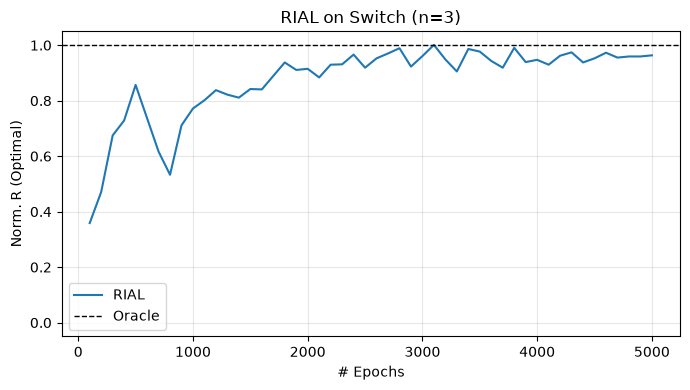


--- Episode 1 ---
day | in room | switch seen | visited | action | sets switch to | reward
  1 | P1      | Off         | 1/3     | None   | On             | +0
  2 | P2      | On          | 2/3     | None   | Off            | +0
  3 | P0      | Off         | 3/3     | None   | Off            | +0
  4 | P1      | Off         | 3/3     | Tell   | -              | +1

--- Episode 2 ---
day | in room | switch seen | visited | action | sets switch to | reward
  1 | P0      | Off         | 1/3     | None   | On             | +0
  2 | P2      | On          | 2/3     | None   | Off            | +0
  3 | P1      | Off         | 3/3     | None   | Off            | +0
  4 | P0      | Off         | 3/3     | Tell   | -              | +1

--- Episode 3 ---
day | in room | switch seen | visited | action | sets switch to | reward
  1 | P2      | Off         | 1/3     | None   | On             | +0
  2 | P1      | On          | 2/3     | None   | Off            | +0
  3 | P1      | Off         | 2/3 

In [9]:
net, history = train(args)